<a href="https://colab.research.google.com/github/BenjaminOrtizO/Estudio/blob/main/EjercicioPPTPronostico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Clonar el repositorio completo
!git clone https://github.com/BenjaminOrtizO/Estudio.git

# Entrar a la carpeta Calidad
%cd /content/Estudio/Pronostico

!git pull

Cloning into 'Estudio'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 50 (delta 11), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 765.91 KiB | 10.35 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/Estudio/Pronostico
Already up to date.


In [4]:
!ls -l

total 160
-rw-r--r-- 1 root root  5593 Oct 15 00:55 itata_calendario.csv
-rw-r--r-- 1 root root 53831 Oct 15 00:55 itata_componentes_verdad.csv
-rw-r--r-- 1 root root 83101 Oct 15 00:55 itata_demanda.csv
-rw-r--r-- 1 root root   220 Oct 15 00:55 itata_jerarquia.csv
-rw-r--r-- 1 root root   439 Oct 15 00:55 itata_maestro_sku.csv
-rw-r--r-- 1 root root     1 Oct 15 00:55 README.md


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#EJERCICIO 1 CARGAR INSPECCIONAR y PARTICIONAR EN EL TIEMPO


In [6]:
demanda = pd.read_csv('itata_demanda.csv')

demanda.head()

,t,semana,iso_anio,iso_semana,sku,familia,formato_g,canal,pedidos_cajas,despachos_cajas,precio_clp_caja,promo,fiestas_patrias,semana_santa,planta_cerrada
0,1,2023-03-06,2023,10,DUR-480,DUR,480,Retail,1456.0,1456.0,21500.0,0,0,0,0
1,2,2023-03-13,2023,11,DUR-480,DUR,480,Retail,1126.0,1126.0,21514.0,0,0,0,0
2,3,2023-03-20,2023,12,DUR-480,DUR,480,Retail,1234.0,1234.0,21528.0,0,0,0,0
3,4,2023-03-27,2023,13,DUR-480,DUR,480,Retail,1452.0,1452.0,21543.0,0,0,0,0
4,5,2023-04-03,2023,14,DUR-480,DUR,480,Retail,1209.0,1209.0,21557.0,0,0,1,0


In [7]:
demanda['semana'] = pd.to_datetime(demanda['semana'])
demanda.head()

demanda['familia'].unique()

x = (demanda[(demanda['familia'] == 'DUR') &(demanda['canal'] == 'Retail')].groupby('semana')['pedidos_cajas'].sum().sort_index())


x = x.asfreq('W-MON')
x.head()

corte = '2024-12-31'


In [8]:
train = x.loc[:corte]
test = x.loc[pd.Timestamp(corte) + pd.offsets.Week(weekday=0):]

In [9]:
print(train.shape, test.shape, x.isna().mean())

(96,) (86,) 0.0


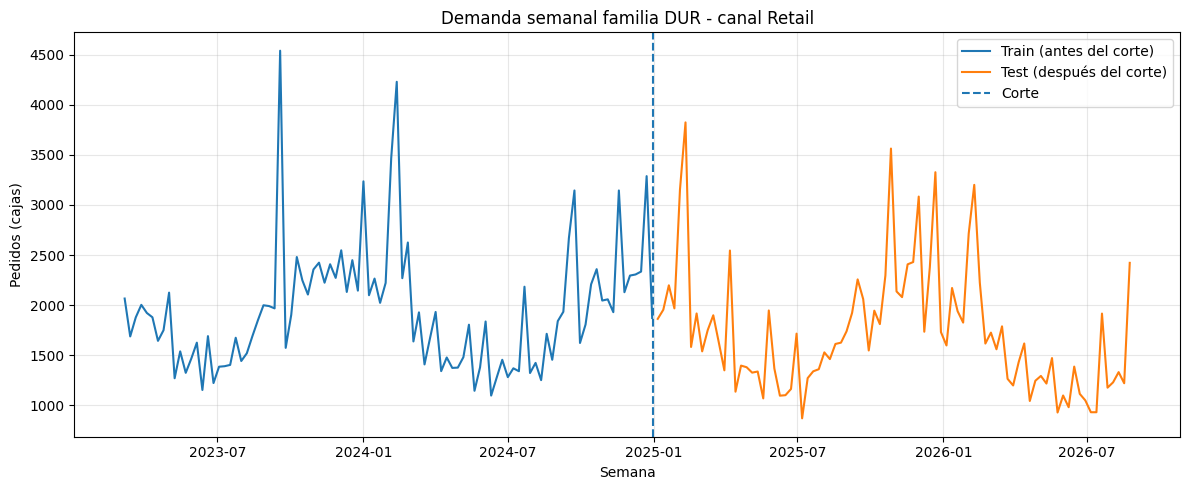

In [10]:


plt.figure(figsize=(12, 5))

plt.plot(train.index, train.values, label='Train (antes del corte)')
plt.plot(test.index, test.values, label='Test (después del corte)')

plt.axvline(pd.Timestamp(corte), linestyle='--', label='Corte')

plt.title('Demanda semanal familia DUR - canal Retail')
plt.xlabel('Semana')
plt.ylabel('Pedidos (cajas)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#EJERCICIO 2

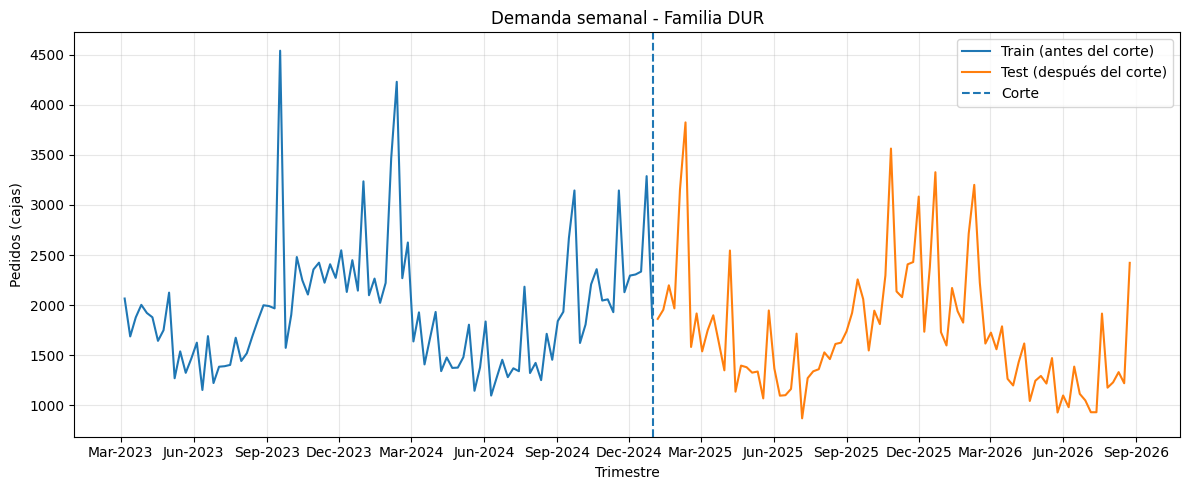

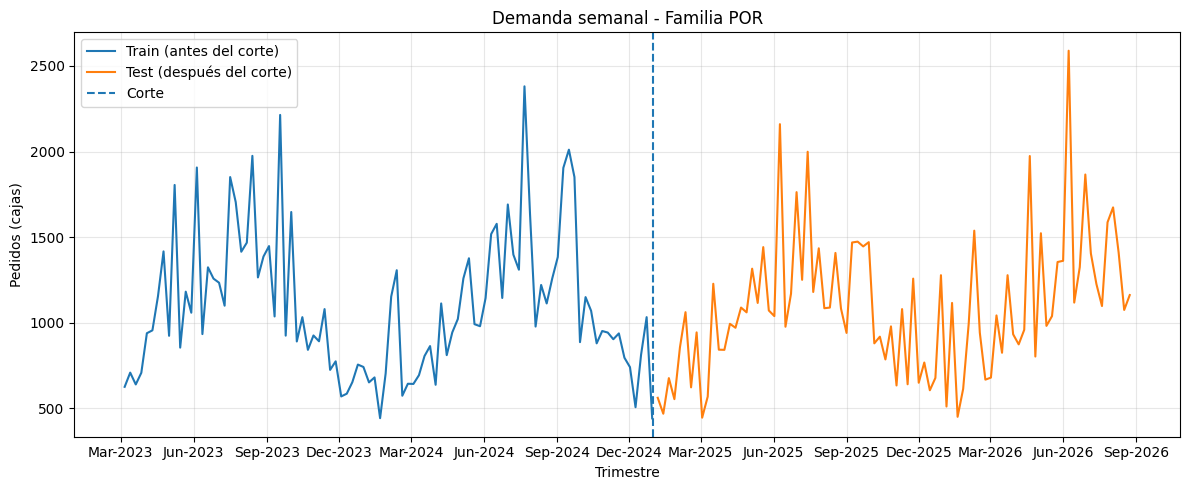

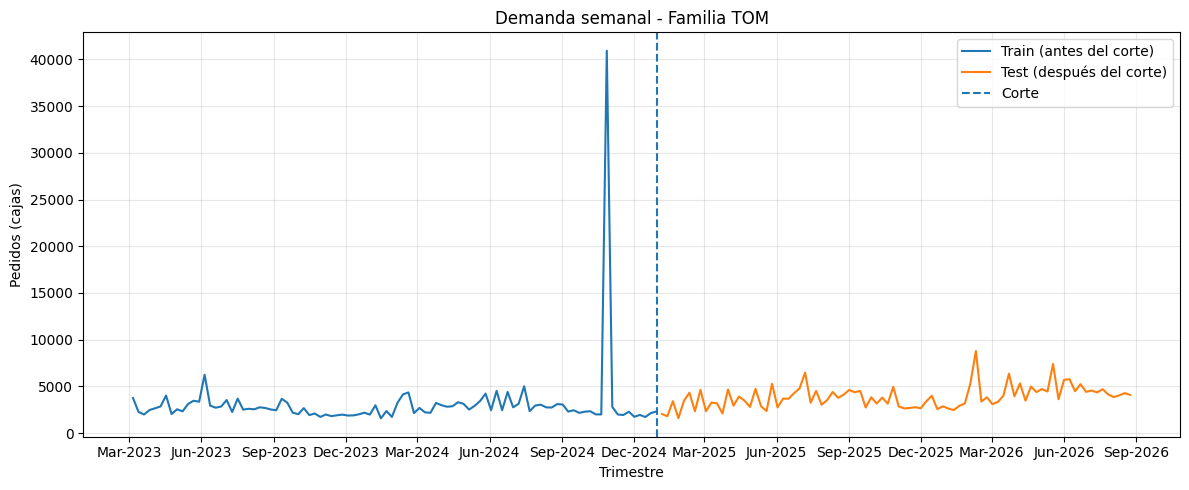

In [15]:
ventas = pd.read_csv('itata_demanda.csv')

# Convertir 'semana' a datetime inmediatamente
ventas['semana'] = pd.to_datetime(ventas['semana'])

corte = pd.to_datetime(corte)

df = (
    ventas.groupby(['familia','semana'])['pedidos_cajas']
    .sum()
    .reset_index()
    .rename(columns={'familia':'unique_id','semana':'ds','pedidos_cajas':'y'})
)

# Ahora sí puedes particionar porque 'ds' ya es datetime
df_train = df[df['ds'] <= corte]
df_test  = df[df['ds'] > corte]





# Generar ticks en marzo, junio, septiembre y diciembre de cada año
ticks = (
    df['ds']
    .dt.to_period('M')
    .drop_duplicates()
    .dt.start_time
)
ticks = ticks[ticks.dt.month.isin([3, 6, 9, 12])]

# 👉 Agregar una etiqueta extra al final (3 meses después del último tick)
ultimo_tick = ticks.max()
extra_tick = ultimo_tick + pd.DateOffset(months=3)

# Convertir a DatetimeIndex y concatenar
ticks = pd.DatetimeIndex(ticks).append(pd.DatetimeIndex([extra_tick]))

# Graficar cada familia
for familia in df['unique_id'].unique():

    train = df_train[df_train['unique_id'] == familia].sort_values('ds')
    test  = df_test[df_test['unique_id'] == familia].sort_values('ds')

    plt.figure(figsize=(12, 5))

    plt.plot(train['ds'], train['y'], label='Train (antes del corte)')
    plt.plot(test['ds'], test['y'], label='Test (después del corte)')

    plt.axvline(corte, color='tab:blue', linestyle='--', label='Corte')

    plt.title(f'Demanda semanal - Familia {familia}')
    plt.xlabel('Trimestre')
    plt.ylabel('Pedidos (cajas)')
    plt.legend()
    plt.grid(alpha=0.3)

    # 👉 Etiquetas en Mar, Jun, Sep, Dic + una extra
    ax = plt.gca()
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks.strftime('%b-%Y'))

    plt.tight_layout()
    plt.show()


In [ ]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive
sf=StatsForecast(
models=[SeasonalNaive(season_length=12), #benchmarkobligatorio
AutoETS(season_length=12)], #ETSelegidoporAICc
freq='W')
sf.fit(df_train)
fc=sf.predict(h=6,level=[80, 95]) #punto+intervalos80/95%